In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("global_earthquakes_seismic.csv")

print("Dataset berhasil dibaca!")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Dataset berhasil dibaca!
Jumlah baris: 10000
Jumlah kolom: 25


,id,time,latitude,longitude,depth,mag,magType,place,status,tsunami,...,gap,type,title,evidence_span,cot_rationale,magnitude_severity_class,focal_depth_regime,tsunami_hazard_potential,tectonic_boundary_zone,confidence_score
0,us6000u20i,1791884908205,-9.9266,118.8246,35.0,4.5,mb,"71 km SW of Tambolaka, Indonesia",reviewed,0,...,123.0,earthquake,"M 4.5 - 71 km SW of Tambolaka, Indonesia",M: 4.5 (mb) | depth: 35.0km | place: '71 km SW...,"Seismic event 'M 4.5 - 71 km SW of Tambolaka, ...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
1,us6000u20g,1791884472899,38.5166,68.8922,10.0,4.7,mb,"9 km NE of Boshkengash, Tajikistan",reviewed,0,...,62.0,earthquake,"M 4.7 - 9 km NE of Boshkengash, Tajikistan",M: 4.7 (mb) | depth: 10.0km | place: '9 km NE ...,"Seismic event 'M 4.7 - 9 km NE of Boshkengash,...",moderate,shallow_crustal,inland_negligible,alpide_himalayan_belt,0.98
2,us6000u207,1791880708325,-28.5560,-12.5205,10.0,5.3,mb,southern Mid-Atlantic Ridge,reviewed,0,...,63.0,earthquake,M 5.3 - southern Mid-Atlantic Ridge,M: 5.3 (mb) | depth: 10.0km | place: 'southern...,Seismic event 'M 5.3 - southern Mid-Atlantic R...,moderate,shallow_crustal,inland_negligible,mid_ocean_ridge_divergent,0.98
3,us6000u1zh,1791873544944,7.7685,-81.4531,10.0,4.7,mb,"14 km WNW of Río Grande, Panama",reviewed,0,...,140.0,earthquake,"M 4.7 - 14 km WNW of Río Grande, Panama",M: 4.7 (mb) | depth: 10.0km | place: '14 km WN...,Seismic event 'M 4.7 - 14 km WNW of Río Grande...,moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
4,us6000u1zc,1791871284155,19.6853,120.7047,10.0,4.7,mb,"124 km N of Pagudpud, Philippines",reviewed,0,...,132.0,earthquake,"M 4.7 - 124 km N of Pagudpud, Philippines",M: 4.7 (mb) | depth: 10.0km | place: '124 km N...,"Seismic event 'M 4.7 - 124 km N of Pagudpud, P...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98


In [4]:
print("Informasi Dataset:")
df.info()

print("\nStatistik Deskriptif:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nData Duplikat:", df.duplicated().sum())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        10000 non-null  object 
 1   time                      10000 non-null  int64  
 2   latitude                  10000 non-null  float64
 3   longitude                 10000 non-null  float64
 4   depth                     10000 non-null  float64
 5   mag                       10000 non-null  float64
 6   magType                   10000 non-null  object 
 7   place                     10000 non-null  object 
 8   status                    10000 non-null  object 
 9   tsunami                   10000 non-null  int64  
 10  sig                       10000 non-null  int64  
 11  net                       10000 non-null  object 
 12  nst                       10000 non-null  int64  
 13  dmin                      10000 non-null  f

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,10000,10000,us6000u20i,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,10000.0,NaN,NaN,NaN,1771917356330.238281,11690270724.464771,1753890068273.0,1760858167777.75,1772139731421.5,1782527070837.75,1791884908205.0
latitude,10000.0,NaN,NaN,NaN,7.828576,31.909441,-67.4686,-15.4493,5.19465,38.385925,85.0643
longitude,10000.0,NaN,NaN,NaN,61.65019,116.440894,-179.997,-32.6293,125.0271,152.264525,179.9899
depth,10000.0,NaN,NaN,NaN,56.165777,101.577053,0.0,10.0,11.0,56.99325,669.556
mag,10000.0,NaN,NaN,NaN,4.812037,0.367266,4.5,4.5,4.7,5.0,7.8
magType,10000,8,mb,8060,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place,10000,6821,South Sandwich Islands region,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,10000,1,reviewed,10000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tsunami,10000.0,NaN,NaN,NaN,0.0084,0.09127,0.0,0.0,0.0,0.0,1.0



Missing Values:


id                          0
time                        0
latitude                    0
longitude                   0
depth                       0
mag                         0
magType                     0
place                       0
status                      0
tsunami                     0
sig                         0
net                         0
nst                         0
dmin                        0
rms                         0
gap                         0
type                        0
title                       0
evidence_span               0
cot_rationale               0
magnitude_severity_class    0
focal_depth_regime          0
tsunami_hazard_potential    0
tectonic_boundary_zone      0
confidence_score            0
dtype: int64


Data Duplikat: 0


In [5]:
numeric_df = df.select_dtypes(include=np.number).copy()

# Menghapus kolom ID jika tersedia
id_columns = [
    col for col in numeric_df.columns
    if any(x in col.lower() for x in ["id", "index", "unnamed"])
]

numeric_df.drop(columns=id_columns, inplace=True)

print("Fitur numerik yang digunakan:")
print(numeric_df.columns.tolist())

display(numeric_df.head())

Fitur numerik yang digunakan:
['time', 'latitude', 'longitude', 'depth', 'mag', 'tsunami', 'sig', 'nst', 'dmin', 'rms', 'gap']


,time,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap
0,1791884908205,-9.9266,118.8246,35.0,4.5,0,312,28,4.966,0.67,123.0
1,1791884472899,38.5166,68.8922,10.0,4.7,0,340,64,1.821,0.70,62.0
2,1791880708325,-28.5560,-12.5205,10.0,5.3,0,432,37,27.968,1.03,63.0
3,1791873544944,7.7685,-81.4531,10.0,4.7,0,340,37,2.117,0.80,140.0
4,1791871284155,19.6853,120.7047,10.0,4.7,0,340,42,3.136,0.95,132.0


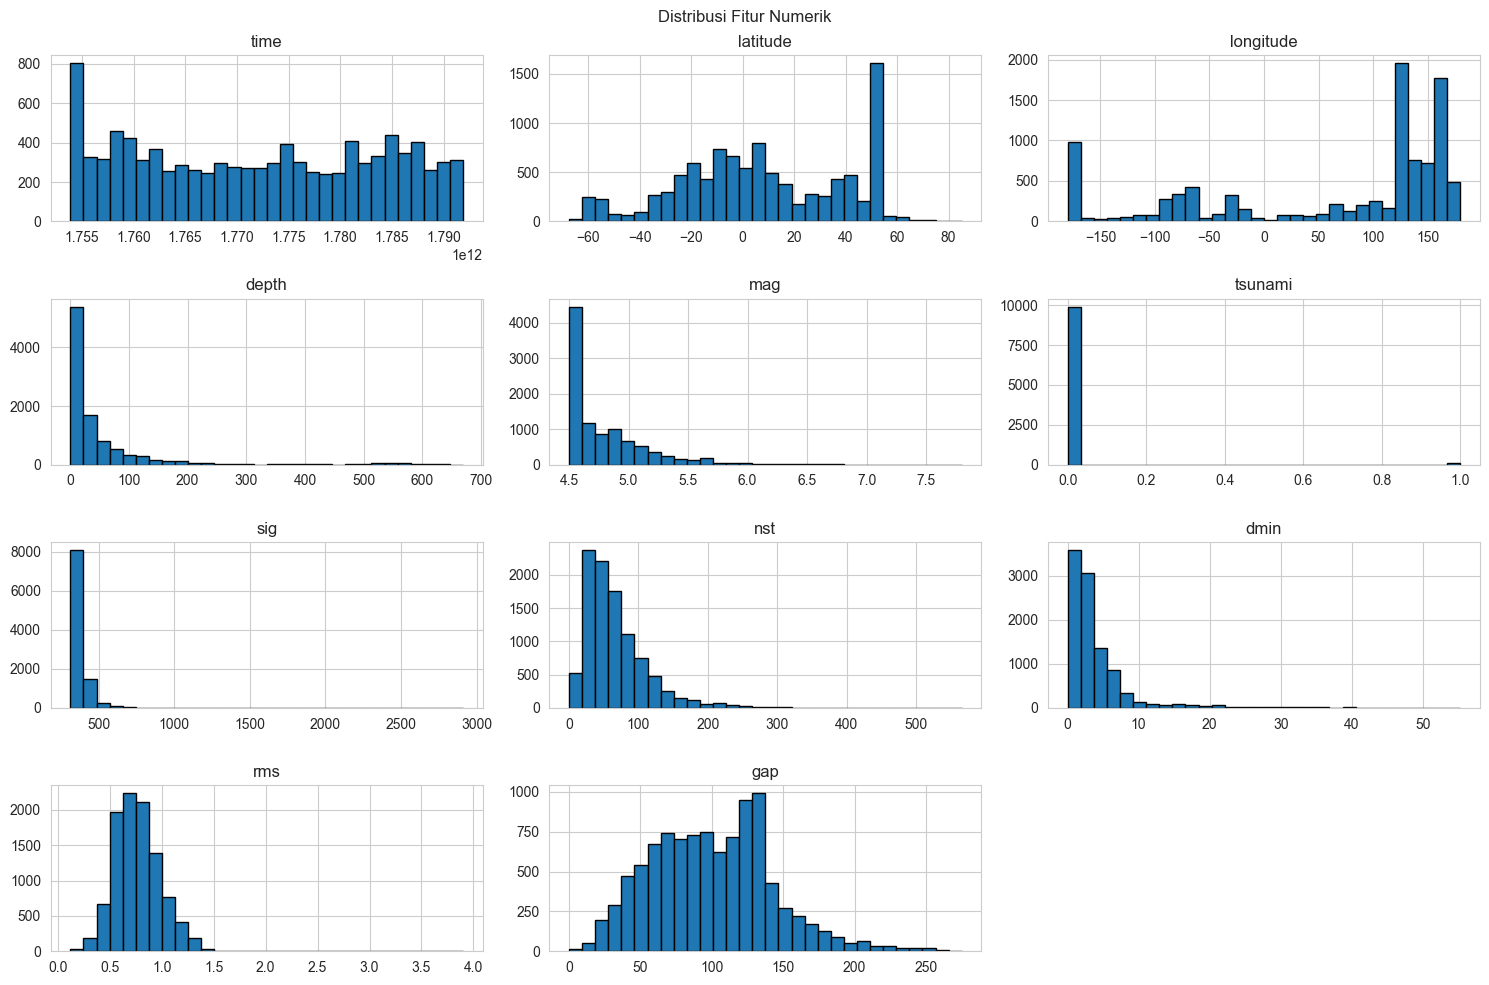

In [6]:
numeric_df.hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribusi Fitur Numerik")
plt.tight_layout()
plt.show()

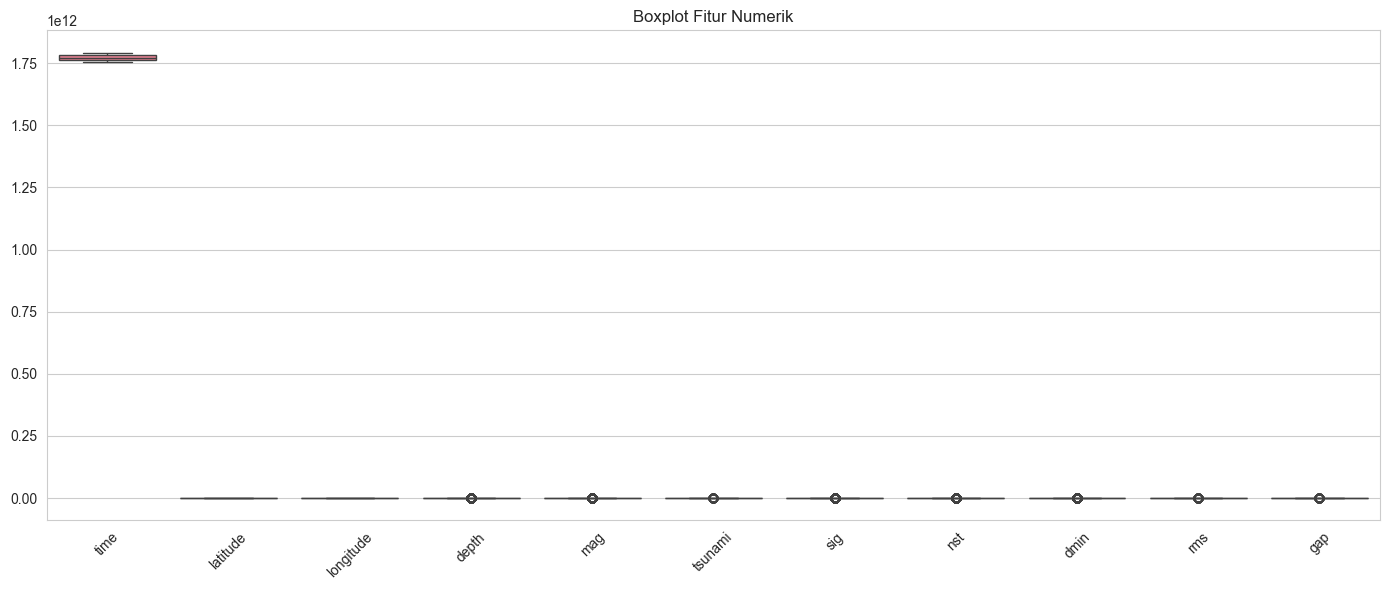

In [7]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=numeric_df)

plt.title("Boxplot Fitur Numerik")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

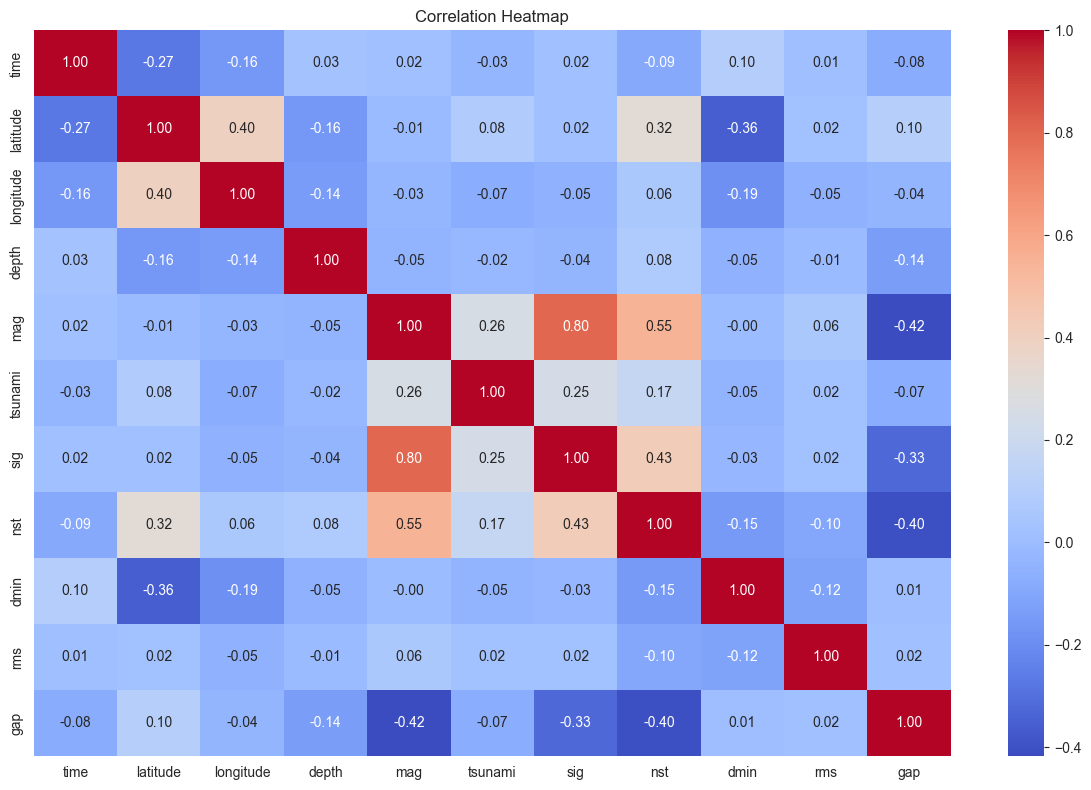

In [8]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [9]:
# Mengubah nilai tak hingga menjadi missing value
numeric_df = numeric_df.replace(
    [np.inf, -np.inf], np.nan
)

# Menghapus data duplikat
numeric_df = numeric_df.drop_duplicates()

# Menghapus kolom yang seluruhnya kosong
numeric_df = numeric_df.dropna(axis=1, how="all")

# Mengisi missing values menggunakan median
imputer = SimpleImputer(strategy="median")

data_imputed = imputer.fit_transform(numeric_df)

numeric_df = pd.DataFrame(
    data_imputed,
    columns=numeric_df.columns
)

print("Preprocessing berhasil!")
print("Jumlah data:", numeric_df.shape[0])
print("Jumlah fitur:", numeric_df.shape[1])

Preprocessing berhasil!
Jumlah data: 10000
Jumlah fitur: 11


In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(numeric_df)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=numeric_df.columns
)

display(X_scaled.head())

,time,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap
0,1.708134,-0.556452,0.491041,-0.208382,-0.849663,-0.092039,-0.575155,-0.827727,0.159226,-0.420492,0.537484
1,1.708097,0.961770,0.062198,-0.454513,-0.305071,-0.092039,-0.256652,-0.059374,-0.438362,-0.284073,-0.888397
2,1.707775,-1.140302,-0.637013,-0.454513,1.328705,-0.092039,0.789858,-0.635639,4.529887,1.216533,-0.865022
3,1.707162,-0.001883,-1.229039,-0.454513,-0.305071,-0.092039,-0.256652,-0.635639,-0.382119,0.170656,0.934860
4,1.706969,0.371593,0.507188,-0.454513,-0.305071,-0.092039,-0.256652,-0.528924,-0.188496,0.852750,0.747860


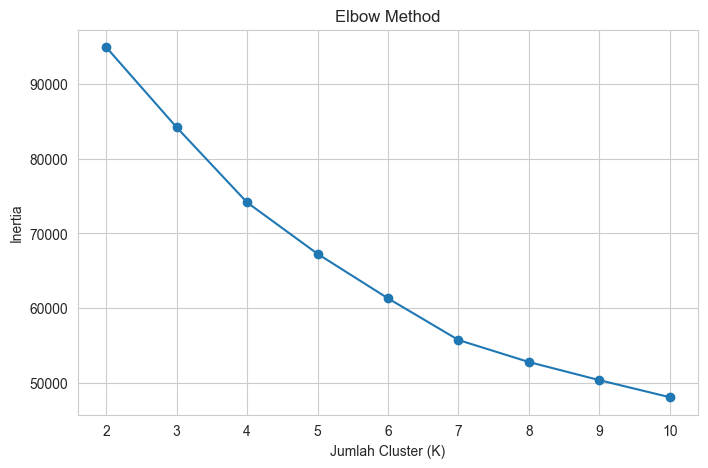

In [11]:
inertia = []

K_range = range(2, 11)

for k in K_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Inertia")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

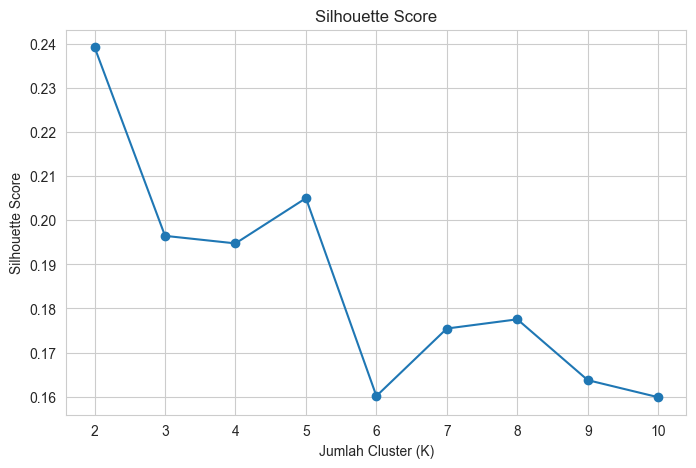

K = 2, Score = 0.2393
K = 3, Score = 0.1965
K = 4, Score = 0.1948
K = 5, Score = 0.2050
K = 6, Score = 0.1601
K = 7, Score = 0.1755
K = 8, Score = 0.1775
K = 9, Score = 0.1637
K = 10, Score = 0.1599


In [12]:
silhouette_scores = []

for k in K_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

for k, score in zip(K_range, silhouette_scores):
    print(f"K = {k}, Score = {score:.4f}")

In [13]:
k_optimal = 3

kmeans = KMeans(
    n_clusters=k_optimal,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

hasil_clustering = numeric_df.copy()

hasil_clustering["cluster"] = cluster_labels

display(hasil_clustering.head())

,time,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap,cluster
0,1.791885e+12,-9.9266,118.8246,35.0,4.5,0.0,312.0,28.0,4.966,0.67,123.0,1
1,1.791884e+12,38.5166,68.8922,10.0,4.7,0.0,340.0,64.0,1.821,0.70,62.0,1
2,1.791881e+12,-28.5560,-12.5205,10.0,5.3,0.0,432.0,37.0,27.968,1.03,63.0,0
3,1.791874e+12,7.7685,-81.4531,10.0,4.7,0.0,340.0,37.0,2.117,0.80,140.0,0
4,1.791871e+12,19.6853,120.7047,10.0,4.7,0.0,340.0,42.0,3.136,0.95,132.0,1


In [14]:
inertia_final = kmeans.inertia_

silhouette_final = silhouette_score(
    X_scaled,
    cluster_labels
)

print("HASIL EVALUASI K-MEANS")
print("======================")
print("Jumlah Cluster:", k_optimal)
print("Inertia:", round(inertia_final, 4))
print("Silhouette Score:", round(silhouette_final, 4))

HASIL EVALUASI K-MEANS
Jumlah Cluster: 3
Inertia: 84218.0927
Silhouette Score: 0.1965


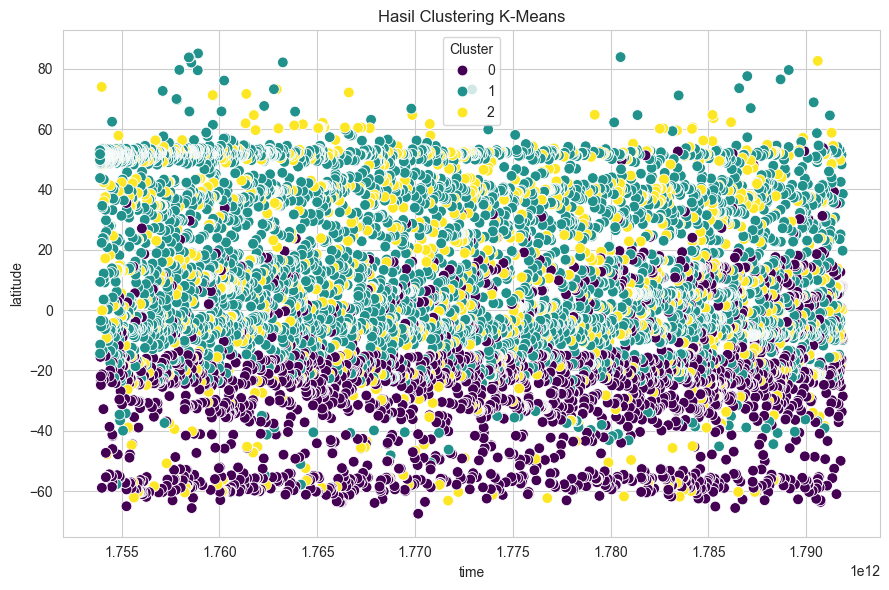

In [15]:
fitur = numeric_df.columns.tolist()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=hasil_clustering,
    x=fitur[0],
    y=fitur[1],
    hue="cluster",
    palette="viridis",
    s=60
)

plt.title("Hasil Clustering K-Means")
plt.xlabel(fitur[0])
plt.ylabel(fitur[1])
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [16]:
ringkasan_cluster = hasil_clustering.groupby(
    "cluster"
).mean(numeric_only=True)

display(ringkasan_cluster)

,time,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap
cluster,,,,,,,,,,,
0,1.775362e+12,-24.234390,-75.891788,93.699542,4.740522,0.00000,347.433781,46.156238,7.681378,0.770250,107.860653
1,1.770318e+12,20.013915,121.913983,39.724935,4.684503,0.00000,338.684824,57.552073,2.825297,0.760626,107.994815
2,1.772150e+12,15.783629,65.810006,55.013672,5.409875,0.05395,477.404624,135.897881,3.067537,0.756375,56.911061


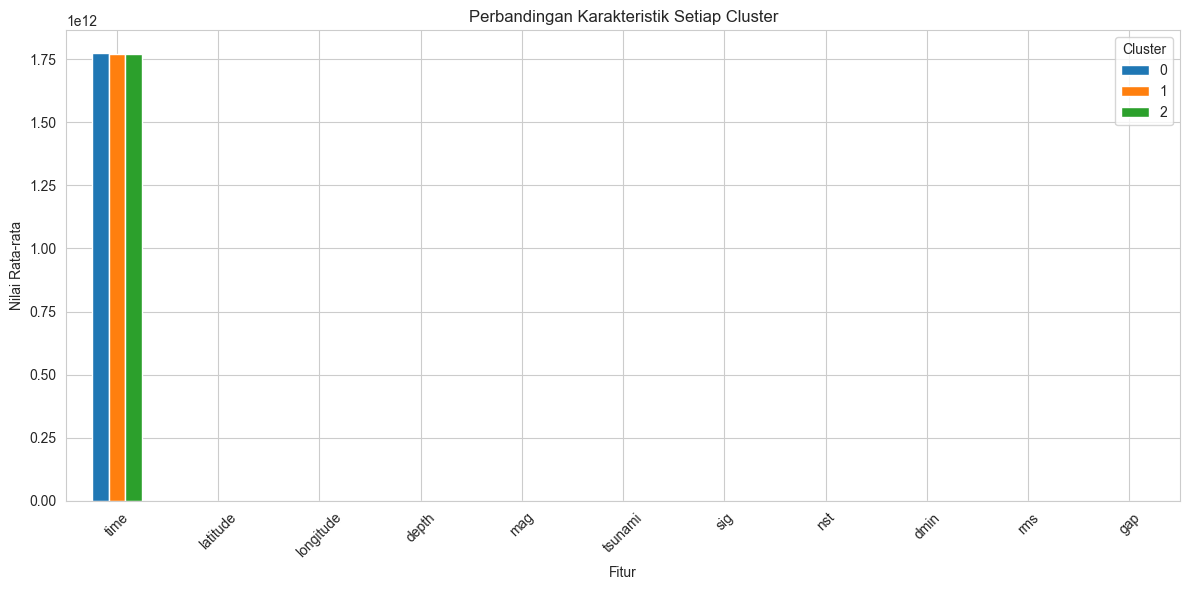

In [17]:
ringkasan_cluster.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Perbandingan Karakteristik Setiap Cluster")
plt.xlabel("Fitur")
plt.ylabel("Nilai Rata-rata")
plt.xticks(rotation=45)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [18]:
import os

os.makedirs("hasil", exist_ok=True)

hasil_clustering.to_csv(
    "hasil/hasil_clustering.csv",
    index=False
)

X_scaled.to_csv(
    "hasil/data_preprocessing.csv",
    index=False
)

ringkasan_cluster.to_csv(
    "hasil/ringkasan_cluster.csv"
)

print("Seluruh hasil berhasil disimpan!")

Seluruh hasil berhasil disimpan!
